# 09 · Build, train, and reload a small U-Net

**Prerequisite:** lesson 08. **Learning time:** 90–120 minutes. **Runs independently:** creates its own data and model.

U-Net combines low-resolution context with high-resolution detail. You will trace its tensor shapes, apply paired augmentation, train with separate validation data, restore the best epoch, and test a saved model.

**Success check:** show disjoint image splits, explain each skip connection, select a checkpoint using validation only, and reproduce its prediction after reload. Our small implementation is inspired by U-Net; it is not an exact reproduction of the original architecture.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


In [2]:
import copy
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from learning.data import make_scene, make_dataset, show_triplet, palette_mask
from learning.torch_models import ArrayDataset, PixelCNN, TinyUNet
from learning.torch_models import run_epoch, confusion_matrix, iou_from_confusion

SEED = 42
FAST_RUN = True  # False increases training; keep True for your first Run All.
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("All DataLoaders use num_workers=0 for a simple Windows notebook workflow.")


PyTorch: 2.11.0+cu128 | device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
All DataLoaders use num_workers=0 for a simple Windows notebook workflow.


## 1. Split before augmenting

Training adjusts weights. Validation selects settings or checkpoints. The test split estimates performance only after those choices are fixed. Real datasets need patient/site/video-level splits when images share a source; random image splitting alone can still leak information.


In [3]:
images, masks = make_dataset(n=60 if FAST_RUN else 300, size=48, seed=19)
ids = np.random.default_rng(SEED).permutation(len(images))
a, b = int(0.6 * len(ids)), int(0.8 * len(ids))
train_ids, val_ids, test_ids = ids[:a], ids[a:b], ids[b:]
assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
print("train / validation / test:", len(train_ids), len(val_ids), len(test_ids))


train / validation / test: 36 12 12


## 2. Apply the same geometry to image and target

A horizontal flip must affect both arrays using the same random decision. Brightness changes belong only on the image. For resizing, images may use bilinear interpolation; masks need **nearest neighbor**, which preserves integer class IDs.

The following function demonstrates both. The training dataset uses random paired flips; the resizing example is a separate explicit inspection.


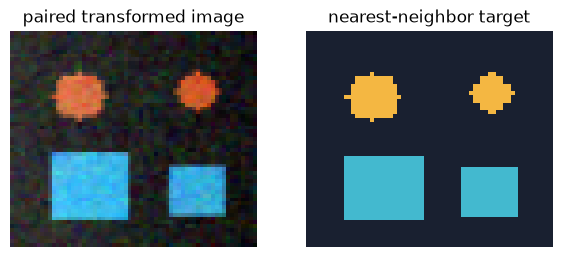

In [4]:
def paired_resize_flip(image, mask, output_size=(48, 48), flip=False):
    x = F.interpolate(image[None], size=output_size, mode="bilinear", align_corners=False)[0]
    y = F.interpolate(mask[None, None].float(), size=output_size, mode="nearest")[0, 0].long()
    if flip:
        x, y = x.flip(-1), y.flip(-1)
    return x, y

sample_x = torch.from_numpy(images[train_ids[0]].transpose(2, 0, 1))
sample_y = torch.from_numpy(masks[train_ids[0]].astype(np.int64))
aug_x, aug_y = paired_resize_flip(sample_x, sample_y, (57, 65), flip=True)
assert set(aug_y.unique().tolist()) <= set(sample_y.unique().tolist())
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(aug_x.permute(1, 2, 0)); axes[0].set_title("paired transformed image")
axes[1].imshow(palette_mask(aug_y.numpy())); axes[1].set_title("nearest-neighbor target")
for ax in axes: ax.axis("off")
plt.show()


In [5]:
train_loader = DataLoader(ArrayDataset(images[train_ids], masks[train_ids], augment=True),
                          batch_size=6, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(ArrayDataset(images[val_ids], masks[val_ids]), batch_size=6, num_workers=0)
test_loader = DataLoader(ArrayDataset(images[test_ids], masks[test_ids]), batch_size=6, num_workers=0)
xb, yb = next(iter(train_loader))
assert xb.shape[1] == 3 and yb.dtype == torch.long
print("training batch:", tuple(xb.shape), tuple(yb.shape))


training batch: (6, 3, 48, 48) (6, 48, 48)


## 3. Read the architecture before running it

The encoder keeps a detailed feature map, pools to half resolution, and learns more channels. A second pooling reaches one-quarter resolution. The decoder upsamples and concatenates the corresponding encoder features along the **channel** axis.

For width 16 and a `48×48` image: `16×48×48 → 32×24×24 → 64×12×12 → 32×24×24 → 16×48×48 → 3×48×48`. The first decoder sees `64+32=96` channels. Interpolating to a skip tensor's actual size also handles odd image dimensions.


In [6]:
class TinyUNet(nn.Module):
    """Two-level U-Net with interpolation to support odd image dimensions."""

    def __init__(self, classes=3, width=16):
        super().__init__()

        def block(ch_in, ch_out):
            return nn.Sequential(
                nn.Conv2d(ch_in, ch_out, 3, padding=1), nn.ReLU(),
                nn.Conv2d(ch_out, ch_out, 3, padding=1), nn.ReLU(),
            )

        self.enc1 = block(3, width)
        self.enc2 = block(width, width * 2)
        self.bridge = block(width * 2, width * 4)
        self.dec2 = block(width * 6, width * 2)
        self.dec1 = block(width * 3, width)
        self.head = nn.Conv2d(width, classes, 1)

    def forward(self, image):
        skip1 = self.enc1(image)
        skip2 = self.enc2(F.max_pool2d(skip1, 2))
        deep = self.bridge(F.max_pool2d(skip2, 2))
        up2 = F.interpolate(deep, size=skip2.shape[-2:], mode="bilinear", align_corners=False)
        decoded2 = self.dec2(torch.cat([up2, skip2], dim=1))
        up1 = F.interpolate(decoded2, size=skip1.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(self.dec1(torch.cat([up1, skip1], dim=1)))


In [7]:
torch.manual_seed(SEED)
UNET_WIDTH = 16
model = TinyUNet(classes=3, width=UNET_WIDTH).to(DEVICE)
assert model(xb.to(DEVICE)).shape == (len(xb), 3, 48, 48)
assert model(torch.rand(1, 3, 49, 53, device=DEVICE)).shape == (1, 3, 49, 53)
print("parameters:", sum(p.numel() for p in model.parameters()))
print("The visible TinyUNet class matches learning/torch_models.py.")


parameters: 118307
The visible TinyUNet class matches learning/torch_models.py.


## 4. Train and keep the best validation checkpoint

We optimize cross-entropy and monitor global macro IoU. Different metrics can select different epochs; state the selection rule before viewing test results. `deepcopy` matters: assigning `best_state = model.state_dict()` alone keeps references to tensors that continue changing.

Early epochs often favor background because it covers many pixels. Watch per-class predictions and the validation curve before deciding that training is broken. The quick run uses 25 short epochs to let this small encoder/decoder move beyond that initial stage; convergence still depends on the data and settings.

The helper `run_epoch` is the same forward/loss/backward loop from lesson 08. It computes a confusion matrix over the full split instead of averaging per-batch IoUs.


In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
epochs = 25 if FAST_RUN else 60
best_score, best_epoch, best_state = -float("inf"), -1, None
history = []
for epoch in range(epochs):
    training = run_epoch(model, train_loader, criterion, optimizer)
    validation = run_epoch(model, val_loader, criterion)
    history.append((training["loss"], validation["loss"], training["miou"], validation["miou"]))
    if validation["miou"] > best_score:
        best_score, best_epoch = validation["miou"], epoch + 1
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    print(f"epoch {epoch+1:02d} | train CE {training['loss']:.3f} | val mIoU {validation['miou']:.3f} | class IoU {validation['iou'].round(3)}")
assert best_state is not None
model.load_state_dict(best_state)
model.eval()
print("Restored best validation epoch:", best_epoch, "with mIoU", round(best_score, 3))


C:\Users\Hareram ray\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


epoch 01 | train CE 1.008 | val mIoU 0.269 | class IoU [0.807 0.    0.   ]
epoch 02 | train CE 0.819 | val mIoU 0.269 | class IoU [0.807 0.    0.   ]
epoch 03 | train CE 0.723 | val mIoU 0.269 | class IoU [0.807 0.    0.   ]
epoch 04 | train CE 0.610 | val mIoU 0.269 | class IoU [0.807 0.    0.   ]


epoch 05 | train CE 0.422 | val mIoU 0.460 | class IoU [0.9   0.481 0.   ]
epoch 06 | train CE 0.282 | val mIoU 0.463 | class IoU [0.96 0.43 0.  ]
epoch 07 | train CE 0.222 | val mIoU 0.483 | class IoU [0.978 0.42  0.051]
epoch 08 | train CE 0.183 | val mIoU 0.719 | class IoU [0.97  0.611 0.577]


epoch 09 | train CE 0.137 | val mIoU 0.892 | class IoU [0.969 0.905 0.803]
epoch 10 | train CE 0.068 | val mIoU 0.965 | class IoU [0.989 0.93  0.975]
epoch 11 | train CE 0.035 | val mIoU 0.956 | class IoU [0.987 0.908 0.972]
epoch 12 | train CE 0.030 | val mIoU 0.963 | class IoU [0.989 0.926 0.973]
epoch 13 | train CE 0.024 | val mIoU 0.969 | class IoU [0.99  0.949 0.968]


epoch 14 | train CE 0.023 | val mIoU 0.968 | class IoU [0.99  0.942 0.97 ]
epoch 15 | train CE 0.019 | val mIoU 0.973 | class IoU [0.992 0.946 0.982]
epoch 16 | train CE 0.018 | val mIoU 0.973 | class IoU [0.992 0.951 0.976]
epoch 17 | train CE 0.017 | val mIoU 0.972 | class IoU [0.991 0.955 0.971]
epoch 18 | train CE 0.017 | val mIoU 0.964 | class IoU [0.989 0.928 0.975]


epoch 19 | train CE 0.018 | val mIoU 0.976 | class IoU [0.993 0.959 0.977]
epoch 20 | train CE 0.014 | val mIoU 0.980 | class IoU [0.994 0.96  0.985]
epoch 21 | train CE 0.013 | val mIoU 0.975 | class IoU [0.993 0.942 0.991]
epoch 22 | train CE 0.013 | val mIoU 0.983 | class IoU [0.995 0.965 0.989]
epoch 23 | train CE 0.013 | val mIoU 0.979 | class IoU [0.994 0.958 0.985]


epoch 24 | train CE 0.012 | val mIoU 0.978 | class IoU [0.993 0.963 0.977]
epoch 25 | train CE 0.014 | val mIoU 0.978 | class IoU [0.994 0.944 0.997]
Restored best validation epoch: 22 with mIoU 0.983


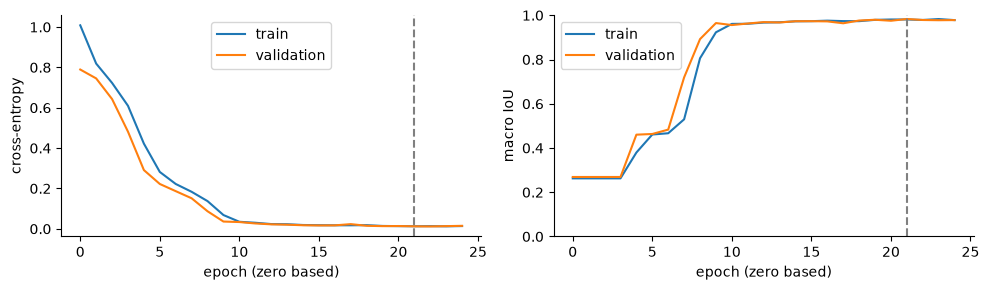

In [9]:
h = np.asarray(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for values, name in [(h[:, 0], "train"), (h[:, 1], "validation")]: axes[0].plot(values, label=name)
for values, name in [(h[:, 2], "train"), (h[:, 3], "validation")]: axes[1].plot(values, label=name)
axes[0].set(ylabel="cross-entropy", xlabel="epoch (zero based)")
axes[1].set(ylabel="macro IoU", xlabel="epoch (zero based)", ylim=(0, 1))
for ax in axes: ax.axvline(best_epoch - 1, color="gray", linestyle="--"); ax.legend()
plt.tight_layout(); plt.show()


## 5. Test once after choosing the checkpoint

This is a tiny illustrative test set, so treat its score as a noisy estimate. Looking at its failures is useful for a new research iteration, but repeatedly optimizing against this same test set turns it into another validation set.


test per-class IoU [background,disk,rectangle]: [0.993 0.961 0.989]
test macro IoU: 0.981


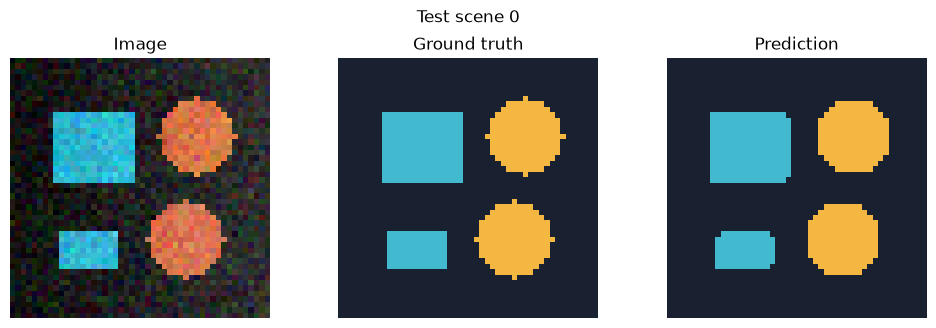

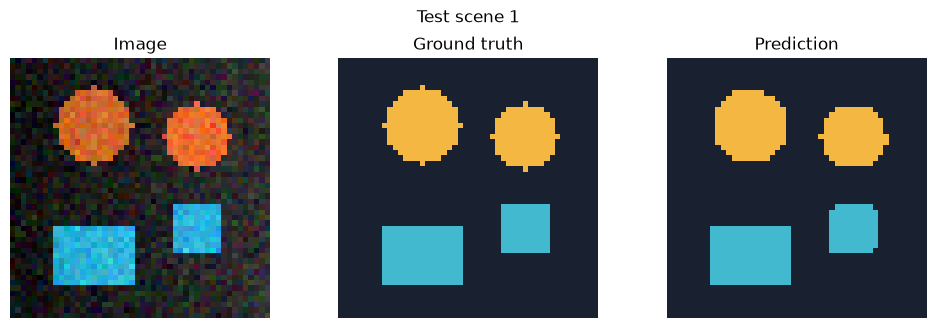

In [10]:
test_result = run_epoch(model, test_loader, criterion)
print("test per-class IoU [background,disk,rectangle]:", test_result["iou"].round(3))
print("test macro IoU:", round(test_result["miou"], 3))
with torch.inference_mode():
    test_x = torch.from_numpy(images[test_ids[:2]].transpose(0, 3, 1, 2)).to(DEVICE)
    test_logits = model(test_x)
    test_prediction = test_logits.argmax(1).cpu().numpy()
for i in range(2):
    show_triplet(images[test_ids[i]], masks[test_ids[i]], test_prediction[i], title=f"Test scene {i}")
    plt.show()


## 6. Save a useful artifact, then prove that reload works

A weight file without architecture and preprocessing information is incomplete. Save class names, shape assumptions, selection metric, and split seed. This is an **inference checkpoint**; exact training resumption would additionally require optimizer, scheduler, and random-generator states.

Only load checkpoints you trust. The example uses your own checkpoint with `weights_only=True` and loads it onto the selected device.


In [11]:
artifact_dir = PROJECT_ROOT / "artifacts" / "09_unet"
artifact_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = artifact_dir / "tiny_unet.pt"
checkpoint = {
    "state_dict": best_state,
    "architecture": "TinyUNet", "width": UNET_WIDTH, "classes": ["background", "disk", "rectangle"],
    "input_range": [0.0, 1.0], "input_layout": "NCHW RGB", "split_seed": SEED,
    "best_epoch": best_epoch, "validation_miou": float(best_score),
    "torch_version": str(torch.__version__),
}
torch.save(checkpoint, checkpoint_path)
loaded = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
reloaded = TinyUNet(classes=len(loaded["classes"]), width=loaded["width"]).to(DEVICE)
reloaded.load_state_dict(loaded["state_dict"]); reloaded.eval()
with torch.inference_mode():
    reloaded_logits = reloaded(test_x)
torch.testing.assert_close(test_logits, reloaded_logits)
print("Reload matches original logits:", checkpoint_path)


Reload matches original logits: C:\Users\Hareram ray\AI\ImageSegmentationPractical\artifacts\09_unet\tiny_unet.pt


## Experiment 1 · Inspect skip-connection shapes

Add temporary forward hooks to `enc1`, `enc2`, and `bridge`. Predict their output shapes before execution. Remove hooks afterward so rerunning does not accumulate print statements.


In [12]:
handles = []
def shape_hook(name):
    return lambda module, inputs, output: print(name, tuple(output.shape))
for name in ["enc1", "enc2", "bridge"]:
    handles.append(getattr(model, name).register_forward_hook(shape_hook(name)))
with torch.inference_mode():
    _ = model(test_x[:1])
for handle in handles: handle.remove()


enc1 (1, 16, 48, 48)
enc2 (1, 32, 24, 24)
bridge (1, 64, 12, 12)


<details><summary>Worked solution 1</summary>

Expected shapes are `(1,16,48,48)`, `(1,32,24,24)`, `(1,64,12,12)`. Concatenation increases channels, not spatial size. The decoder upsamples first because a `12×12` tensor cannot be concatenated with a `24×24` skip along channels.
</details>

## Experiment 2 · A fair augmentation ablation

Compare paired flips on versus off. Recreate model, optimizer, shuffled loader, and random seeds for each run. Use the same validation IDs and training budget. Leave the test split closed during this comparison.


<details><summary>Worked solution 2</summary>

Use `ArrayDataset(images[train_ids], masks[train_ids], augment=False)` for the second condition. Reset `torch.manual_seed(SEED)` before creating each model and initialize both loader generators with the same seed. Record best validation mIoU and per-class IoU. A single seed and this symmetric toy dataset may show little or no benefit; repeat several seeds before drawing a conclusion.
</details>

## Experiment 3 · Overfit two images as a debugging test

Build a training loader containing only two images, turn augmentation off, and train longer. The target is near-perfect **training** segmentation. Why is this useful even though it does not measure generalization?


<details><summary>Worked solution 3</summary>

Use `DataLoader(ArrayDataset(images[train_ids[:2]], masks[train_ids[:2]]), batch_size=2, num_workers=0)`. Create a fresh TinyUNet and optimizer, then train for 100–200 small steps. If loss cannot fall, check labels, model output channels, gradients, normalization, and whether the optimizer owns this model's parameters. Success shows the pipeline can fit these examples; it does not prove the model generalizes.
</details>


## Checkpoint and common errors

- Trace the 96 decoder channels back to `64 + 32`.
- Distinguish bilinear image resizing from nearest-neighbor label resizing.
- Show that train/validation/test IDs do not overlap.
- Explain why the final training epoch may differ from the saved epoch.
- A device mismatch means model and tensors must both move to `DEVICE`.
- A shape mismatch at concatenation means the spatial sizes must be aligned before `torch.cat`.
- Save after selecting the best validation state; never select with test IoU.


## References and next step

- [Original U-Net paper](https://arxiv.org/abs/1505.04597)
- [PyTorch interpolation API](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.interpolate.html)
- [PyTorch saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)

Continue with **10_real_data_transfer_learning.ipynb** to replace arrays with image/mask folders and explore optional pretrained transfer learning.
